# Caspase-3/7 Pattern Analysis — Cell Line Comparisons
Analysing activity patterns across **14 assays / cell lines** using `consistent_compounds_caspase_all.csv`

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from itertools import combinations

plt.rcParams['figure.dpi'] = 120
print('Libraries loaded!')

Libraries loaded!


In [4]:
# ── Load data ──────────────────────────────────────────────────────────────
DATA = "/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/all_cell_line_comparisions/consistent_compounds_caspase_all.csv"
df = pd.read_csv(DATA)

# Cell-line columns only (exclude PUBCHEM_CID, pattern, behavior)
ASSAY_COLS = [c for c in df.columns if c not in ('PUBCHEM_CID', 'pattern', 'behavior')]

#  short names for plots
SHORT = {
    'AID_1346980'                : 'CHO-K1',
    'AID_655'                    : 'Jurkat',
    'AID_656'                    : 'HUV-EC-C',
    'AID_657'                    : 'SHSY5Y',
    'AID_658'                    : 'BJ',
    'AID_659'                    : 'MRC-5',
    'AID_660'                    : 'Mesangial',
    'AID_661'                    : 'SK-N-SH',
    'AID_663'                    : 'H-4-II-E',
    'AID_664'                    : 'Hek293',
    'AID_665'                    : 'N2a',
    'AID_666'                    : 'NIH 3T3',
    'AID_667'                    : 'Renal Proximal Tubule',
    'combined_hepg2_casepase.csv': 'HepG2',
}

print(f'Total CIDs : {len(df)}')
print(f'Assays     : {len(ASSAY_COLS)}')
print(f'\nBehavior counts:')
print(df['behavior'].value_counts())

Total CIDs : 7716
Assays     : 14

Behavior counts:
behavior
Inactive                                    6967
Mixed (Inactive + Inconclusive)              359
Mixed (Active + Inactive)                    110
Mixed (Active + Inactive + Inconclusive)      77
Mixed (Active + Inconclusive)                 70
Inconclusive                                  67
Active                                        66
Name: count, dtype: int64


In [5]:
# A1. How many CIDs are Active in at least one assay?
active_mask = (df[ASSAY_COLS] == 'Active').any(axis=1)
n_active    = active_mask.sum()
n_total     = len(df)
print(f'Active in ≥1 assay : {n_active} / {n_total}  ({100*n_active/n_total:.1f}%)')
print(f'Never active       : {n_total - n_active} / {n_total}  ({100*(n_total-n_active)/n_total:.1f}%)')

Active in ≥1 assay : 323 / 7716  (4.2%)
Never active       : 7393 / 7716  (95.8%)


In [6]:
n_active
print(n_active)
#print the rows where the compound is active in at least one assay
active_cids = df[active_mask]

print(active_cids)

323
      PUBCHEM_CID AID_1346980       AID_655       AID_656   AID_657  \
7134         2247      Active           NaN           NaN       NaN   
7135         2799      Active           NaN           NaN       NaN   
7136         3191      Active           NaN           NaN       NaN   
7137         4807      Active           NaN           NaN       NaN   
7138         5154      Active           NaN           NaN       NaN   
...           ...         ...           ...           ...       ...   
7705        64142         NaN        Active      Inactive  Inactive   
7706      5284643         NaN        Active  Inconclusive  Inactive   
7711      6537491         NaN  Inconclusive      Inactive  Inactive   
7712         8722         NaN  Inconclusive      Inactive  Inactive   
7713      5284626         NaN  Inconclusive      Inactive  Inactive   

           AID_658       AID_659       AID_660       AID_661       AID_663  \
7134           NaN           NaN           NaN           NaN     

In [7]:
active_cids.to_csv("/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/all_cell_line_comparisions/caspase_atleast_one_active.csv", index=False)

In [8]:
# Count the number of assays where each CID is Active
active_counts = (df[ASSAY_COLS] == 'Active').sum(axis=1)

# Filter CIDs that are Active in more than one assay
active_in_multiple = active_counts[active_counts > 1]
n_active_multiple = len(active_in_multiple)

print(f'Active in >1 assay: {n_active_multiple} CIDs')
# Count the occurrences of each pattern
pattern_counts = df['pattern'].value_counts()

# Filter patterns that occur more than once
patterns_with_multiple = pattern_counts[pattern_counts >1]
n_patterns_multiple = len(patterns_with_multiple)

print(f'Patterns with >1 occurrence: {n_patterns_multiple}')


Active in >1 assay: 111 CIDs
Patterns with >1 occurrence: 41


In [9]:
#CHECKING IN PATTERN 1 
# Filter compounds inactive in AID_1346980
inactive_in_aid = df[df['AID_1346980'] == 'Inactive']

# Check if they are also inactive in HepG2
overlap = inactive_in_aid[inactive_in_aid['combined_hepg2_casepase.csv'] == 'Inactive']

# Calculate the percentage of overlap
total_inactive_in_aid = len(inactive_in_aid)
overlap_count = len(overlap)
percentage_overlap = (overlap_count / total_inactive_in_aid) * 100 if total_inactive_in_aid > 0 else 0

print(f"Total inactive in AID_1346980: {total_inactive_in_aid}")
print(f"Overlap (also inactive in HepG2): {overlap_count}")
print(f"Percentage overlap: {percentage_overlap:.2f}%")

#THESE CIDS ARE IN THE FIRST GROUP 


Total inactive in AID_1346980: 7320
Overlap (also inactive in HepG2): 7028
Percentage overlap: 96.01%


In [10]:
#AID_1346980=Inactive | AID_655=Inactive | AID_656=Inactive | AID_657=Inactive | AID_658=Inactive | AID_659=Inactive | AID_660=Inactive | AID_661=Inactive | AID_663=Inactive | AID_664=Inactive | AID_665=Inactive | AID_666=Inactive | AID_667=Inactive | combined_hepg2_casepase.csv=Inactive      1026
# This pattern indicates that there are 1026 compounds that are consistently inactive across all the listed assays, including both AID_1346980 and combined_hepg2_casepase.csv. This suggests that these compounds do not show activity in any of the tested cell lines, which could imply that they are not effective in inducing caspase activity or may have no biological effect in these contexts.

---
## J — Active CID Pattern Analysis
Simple block-by-block exploration of what active CIDs look like across cell lines.

### J1 — For each active CID: how many cell lines is it active in?
Each CID gets a score = number of assays it is Active in. Higher score = stronger, more consistent caspase inducer.

How many cell lines each active CID is Active in:
n_active
1     212
2      80
3      13
4       5
5       2
6       4
7       3
8       1
9       1
10      2
Name: count, dtype: int64


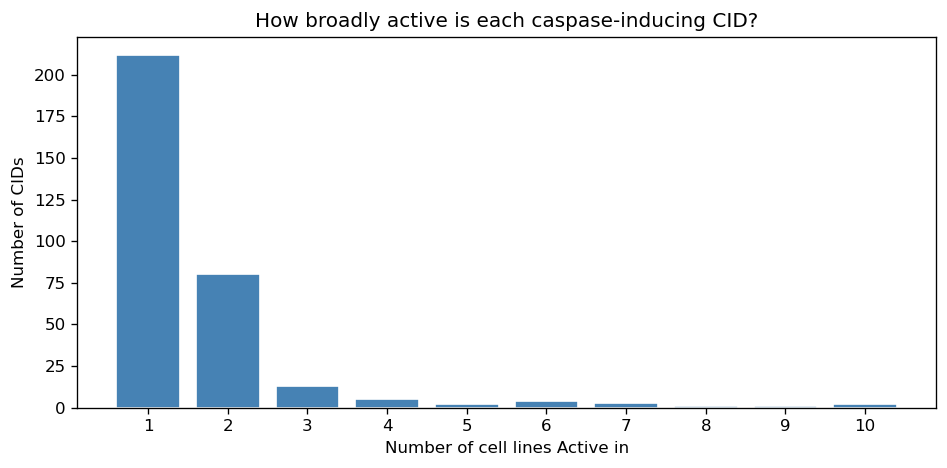


Top 10 CIDs by breadth of activity:
 PUBCHEM_CID  n_active  n_inactive  n_inc
       11057        10           0      4
     5288209        10           1      3
     2724411         9           1      4
       62770         8           1      5
      457193         7           5      2
      108005         7           5      2
      443939         7           6      1
     2723598         6           4      4
       19042         6           4      4
     5284469         6           1      7


In [11]:
# J1 — Score each active CID by how many assays it is Active in
active_mask = (df[ASSAY_COLS] == 'Active').any(axis=1)
adf = df[active_mask].copy()
adf['n_active']   = (adf[ASSAY_COLS] == 'Active').sum(axis=1)
adf['n_inactive'] = (adf[ASSAY_COLS] == 'Inactive').sum(axis=1)
adf['n_inc']      = (adf[ASSAY_COLS] == 'Inconclusive').sum(axis=1)

# Distribution: how many CIDs hit exactly 1 assay, 2 assays, etc.
score_dist = adf['n_active'].value_counts().sort_index()
print("How many cell lines each active CID is Active in:")
print(score_dist)

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(score_dist.index, score_dist.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Number of cell lines Active in')
ax.set_ylabel('Number of CIDs')
ax.set_title('How broadly active is each caspase-inducing CID?')
ax.xaxis.set_major_locator(mticker.MultipleLocator(1))
plt.tight_layout()
plt.show()

# Top 10 most broadly active CIDs
print("\nTop 10 CIDs by breadth of activity:")
top10 = adf.nlargest(10, 'n_active')[['PUBCHEM_CID', 'n_active', 'n_inactive', 'n_inc']]
print(top10.to_string(index=False))  #include 

### J2 — "Active here, Inactive there" — the flip-flop CIDs
These are the most interesting: a CID is Active in at least one cell line AND Inactive in at least one other.
That means the compound works in some cells but does NOT work in others — cell-line specific behaviour.

In [12]:
# J2 — Flip-flop CIDs: Active in some cell lines, Inactive in others
flipflop = adf[(adf['n_active'] >= 1) & (adf['n_inactive'] >= 1)].copy()
flipflop = flipflop.sort_values(['n_active', 'n_inactive'], ascending=False)

print(f"Flip-flop CIDs (Active in ≥1 AND Inactive in ≥1 cell line): {len(flipflop)}")
print(f"Out of all {len(adf)} active CIDs\n")

# For each flip-flop CID, show exactly where it is active vs inactive
rows = []
for _, r in flipflop.iterrows():
    active_in   = [SHORT.get(c, c) for c in ASSAY_COLS if r[c] == 'Active']
    inactive_in = [SHORT.get(c, c) for c in ASSAY_COLS if r[c] == 'Inactive']
    rows.append({
        'PUBCHEM_CID' : int(r['PUBCHEM_CID']),
        'active_in_n' : int(r['n_active']),
        'inactive_in_n': int(r['n_inactive']),
        'active_in'   : ', '.join(active_in),
        'inactive_in' : ', '.join(inactive_in),
    })

ff_df = pd.DataFrame(rows)
print("Top 20 flip-flop CIDs (sorted by most Active assays first):")
ff_df.head(20)

Flip-flop CIDs (Active in ≥1 AND Inactive in ≥1 cell line): 187
Out of all 323 active CIDs

Top 20 flip-flop CIDs (sorted by most Active assays first):


,PUBCHEM_CID,active_in_n,inactive_in_n,active_in,inactive_in
0,5288209,10,1,"Jurkat, HUV-EC-C, MRC-5, Mesangial, SK-N-SH, H...",NIH 3T3
1,2724411,9,1,"CHO-K1, Mesangial, SK-N-SH, H-4-II-E, Hek293, ...",HUV-EC-C
2,62770,8,1,"CHO-K1, Jurkat, MRC-5, SK-N-SH, H-4-II-E, N2a,...",HUV-EC-C
3,443939,7,6,"Jurkat, SHSY5Y, SK-N-SH, H-4-II-E, N2a, NIH 3T...","HUV-EC-C, BJ, MRC-5, Mesangial, Hek293, Renal ..."
4,457193,7,5,"CHO-K1, Jurkat, SK-N-SH, H-4-II-E, N2a, NIH 3T...","HUV-EC-C, BJ, MRC-5, Mesangial, Hek293"
5,108005,7,5,"Jurkat, BJ, MRC-5, SK-N-SH, NIH 3T3, Renal Pro...","CHO-K1, Mesangial, H-4-II-E, Hek293, N2a"
6,6294,6,5,"SHSY5Y, Mesangial, H-4-II-E, Hek293, Renal Pro...","Jurkat, BJ, MRC-5, SK-N-SH, NIH 3T3"
7,2723598,6,4,"CHO-K1, Jurkat, SHSY5Y, H-4-II-E, NIH 3T3, HepG2","HUV-EC-C, MRC-5, Mesangial, Renal Proximal Tubule"
8,19042,6,4,"CHO-K1, Jurkat, SHSY5Y, SK-N-SH, N2a, HepG2","HUV-EC-C, Hek293, NIH 3T3, Renal Proximal Tubule"
9,5284469,6,1,"CHO-K1, SHSY5Y, BJ, SK-N-SH, Hek293, HepG2",NIH 3T3


### J3 — Inconclusive as a soft signal: does it induce caspase?
Are there more patterns with more inconclusive and active like a group of cid across different cell lines 


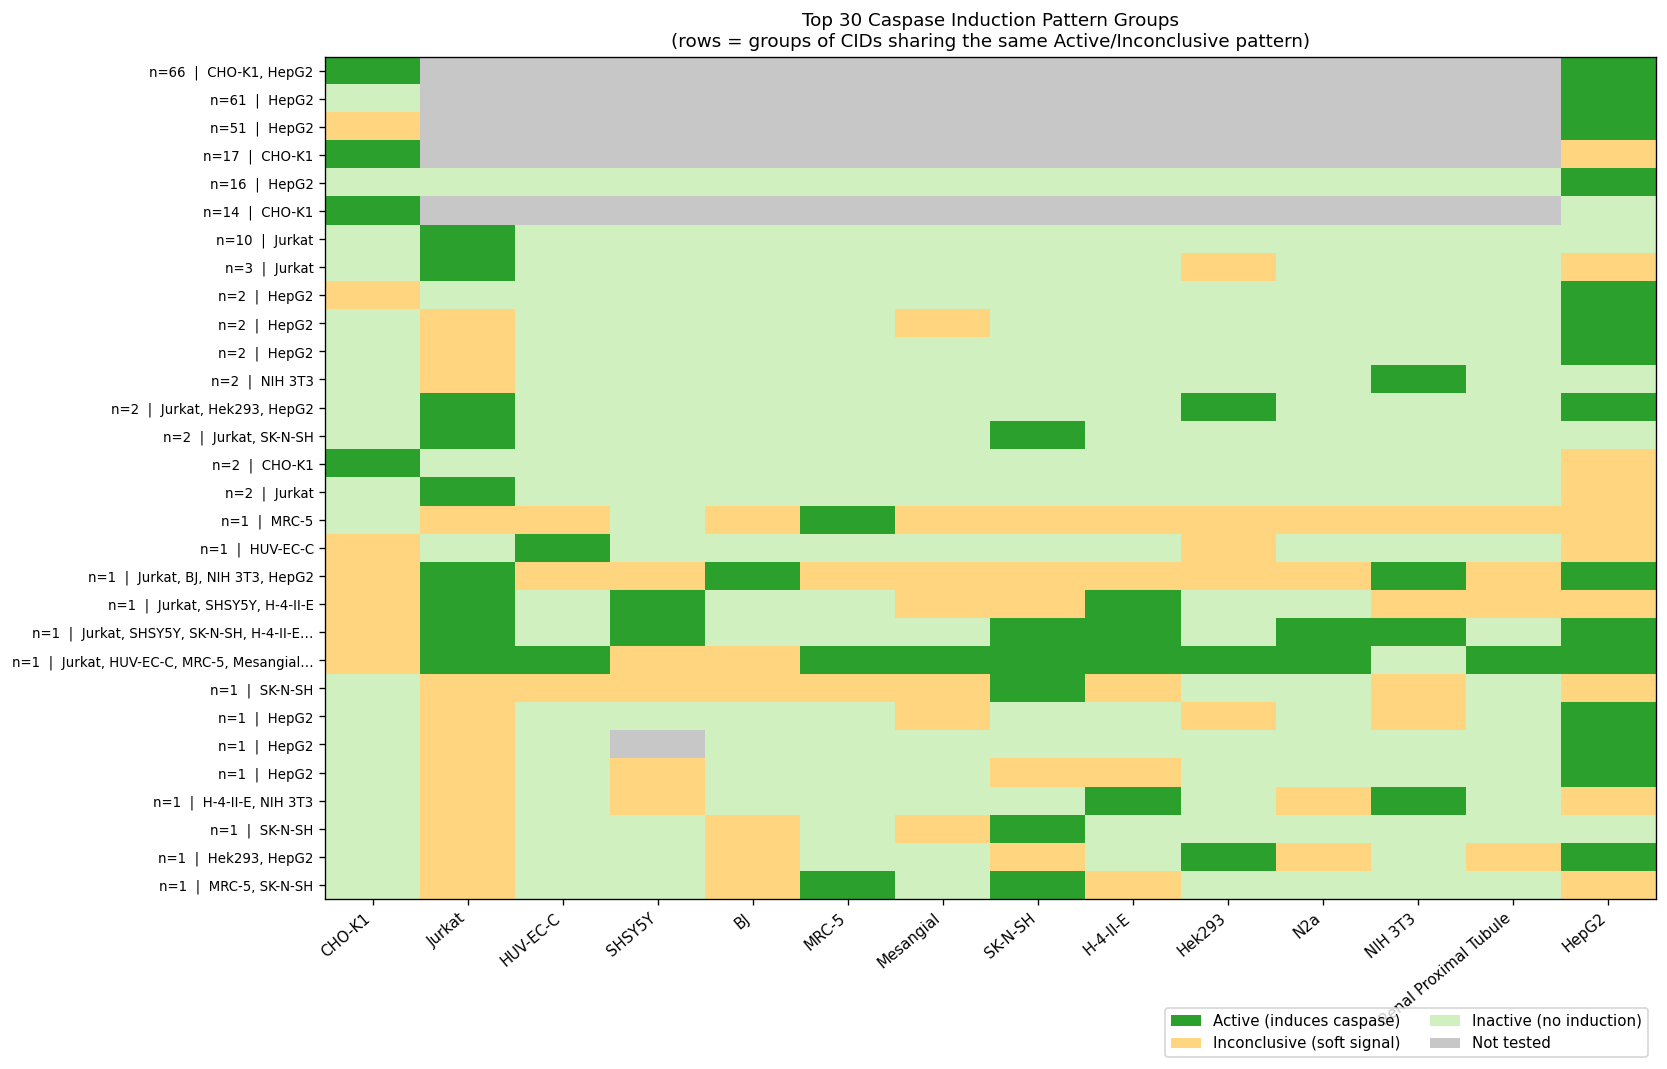

Top 30 pattern groups — Active/Inconclusive breakdown per group:

   66 CIDs | Active in: ['CHO-K1', 'HepG2']

   61 CIDs | Active in: ['HepG2']

   51 CIDs | Active in: ['HepG2']
          | Inconclusive in: ['CHO-K1']

   17 CIDs | Active in: ['CHO-K1']
          | Inconclusive in: ['HepG2']

   16 CIDs | Active in: ['HepG2']

   14 CIDs | Active in: ['CHO-K1']

   10 CIDs | Active in: ['Jurkat']

    3 CIDs | Active in: ['Jurkat']
          | Inconclusive in: ['Hek293', 'HepG2']

    2 CIDs | Active in: ['HepG2']
          | Inconclusive in: ['CHO-K1']

    2 CIDs | Active in: ['HepG2']
          | Inconclusive in: ['Jurkat', 'Mesangial']

    2 CIDs | Active in: ['HepG2']
          | Inconclusive in: ['Jurkat']

    2 CIDs | Active in: ['NIH 3T3']
          | Inconclusive in: ['Jurkat']

    2 CIDs | Active in: ['Jurkat', 'Hek293', 'HepG2']

    2 CIDs | Active in: ['Jurkat', 'SK-N-SH']

    2 CIDs | Active in: ['CHO-K1']
          | Inconclusive in: ['HepG2']

    2 CIDs | Active 

In [13]:
# Active vs Inconclusive pattern groups — heatmap across cell lines
#
# For every active CID, build a signature tuple:
#   A = Active in that cell line
#   I = Inconclusive
#   X = Inactive
#   . = not tested (NaN)
#
# CIDs that share the SAME signature are in the same group.
# The heatmap shows each group as a row so you can see:
# "this group is Active in HepG2/Jurkat but Inconclusive in CHO-K1"

from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ── 1. Build per-CID signature ────────────────────────────────────────────────
active_mask = (df[ASSAY_COLS] == 'Active').any(axis=1)
adf = df[active_mask].copy().reset_index(drop=True)

LABEL_MAP = {'Active': 'A', 'Inconclusive': 'I', 'Inactive': 'X'}

def make_sig(row):
    return tuple(LABEL_MAP.get(row[c], '.') for c in ASSAY_COLS)

adf['sig'] = adf.apply(make_sig, axis=1)

# ── 2. Count CIDs per signature, keep top 30 ─────────────────────────────────
sig_counts = adf['sig'].value_counts()
top_sigs   = sig_counts.head(30).index.tolist()

# ── 3. Build numeric matrix for heatmap ──────────────────────────────────────
# A=2 (Active), I=1 (Inconclusive), X=0 (Inactive), .=-1 (not tested)
NUM = {'A': 2, 'I': 1, 'X': 0, '.': -1}

rows_h, ylabels = [], []
for sig in top_sigs:
    rows_h.append([NUM[s] for s in sig])
    n = sig_counts[sig]
    # summarise label: which cell lines are Active?
    active_cls = [SHORT.get(ASSAY_COLS[i], ASSAY_COLS[i])
                  for i, s in enumerate(sig) if s == 'A']
    ylabels.append(f"n={n}  |  {', '.join(active_cls[:4])}{'…' if len(active_cls)>4 else ''}")

mat = np.array(rows_h, dtype=float)
xlabels = [SHORT.get(c, c) for c in ASSAY_COLS]

# ── 4. Plot heatmap ───────────────────────────────────────────────────────────
cmap   = ListedColormap(['#c7c7c7', '#d0f0c0', '#ffd580', '#2ca02c'])
# values: -1 → light grey (not tested), 0 → light green (Inactive),
#          1 → orange (Inconclusive), 2 → dark green (Active)

fig, ax = plt.subplots(figsize=(14, 9))
im = ax.imshow(mat, aspect='auto', cmap=cmap, vmin=-1, vmax=2)

ax.set_xticks(range(len(xlabels)))
ax.set_xticklabels(xlabels, rotation=40, ha='right', fontsize=9)
ax.set_yticks(range(len(ylabels)))
ax.set_yticklabels(ylabels, fontsize=8)
ax.set_title('Top 30 Caspase Induction Pattern Groups\n'
             '(rows = groups of CIDs sharing the same Active/Inconclusive pattern)',
             fontsize=11)

legend_elements = [
    Patch(facecolor='#2ca02c', label='Active (induces caspase)'),
    Patch(facecolor='#ffd580', label='Inconclusive (soft signal)'),
    Patch(facecolor='#d0f0c0', label='Inactive (no induction)'),
    Patch(facecolor='#c7c7c7', label='Not tested'),
]
ax.legend(handles=legend_elements, loc='upper right',
          bbox_to_anchor=(1.0, -0.12), ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

# ── 5. Print summary table ────────────────────────────────────────────────────
print("Top 30 pattern groups — Active/Inconclusive breakdown per group:\n")
for sig in top_sigs:
    n      = sig_counts[sig]
    act_cl = [SHORT.get(ASSAY_COLS[i], ASSAY_COLS[i]) for i, s in enumerate(sig) if s == 'A']
    inc_cl = [SHORT.get(ASSAY_COLS[i], ASSAY_COLS[i]) for i, s in enumerate(sig) if s == 'I']
    print(f"  {n:3d} CIDs | Active in: {act_cl or ['—']}")
    if inc_cl:
        print(f"          | Inconclusive in: {inc_cl}")
    print()

### Fully tested CIDs — what do they say about caspase induction?
Only CIDs tested in **all 14 cell lines** 

In [14]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# ── 1. Filter: tested in ALL 14 cell lines ────────────────────────────────────
all14 = df[df[ASSAY_COLS].notna().all(axis=1)].copy()

never_active = ~(all14[ASSAY_COLS] == 'Active').any(axis=1)
always_inact = (all14[ASSAY_COLS] == 'Inactive').all(axis=1)
always_inc   = (all14[ASSAY_COLS] == 'Inconclusive').all(axis=1)
# never Active but a mix of Inactive + Inconclusive across the 14 cell lines
mixed_no_act = never_active & ~always_inact & ~always_inc

n_active_any = (~never_active).sum()
n_always_ina = always_inact.sum()
n_always_inc = always_inc.sum()
n_mixed      = mixed_no_act.sum()
total        = len(all14)

print(f"CIDs tested in all 14 cell lines : {total}")
print(f"  Active in ≥1 cell line         : {n_active_any}")
print(f"  Always Inactive  (all 14=Inact) : {n_always_ina}")
print(f"  Always Inconclusive (all 14=Inc): {n_always_inc}")
print(f"  Mix of Inactive + Inconclusive  : {n_mixed}   ← never Active, but not purely Inactive")
print(f"  ──────────────────────────────────────────")
print(f"  Sum check                       : {n_active_any + n_always_ina + n_always_inc + n_mixed}  (must = {total})")
print()

# ── 2. Focus on the active ones ───────────────────────────────────────────────
active14 = all14[(all14[ASSAY_COLS] == 'Active').any(axis=1)].copy()
active14['n_active'] = (active14[ASSAY_COLS] == 'Active').sum(axis=1)
active14['n_inc']    = (active14[ASSAY_COLS] == 'Inconclusive').sum(axis=1)

# ── 3. Build signature (A/I/X only — no gaps here) ───────────────────────────
LABEL_MAP = {'Active': 'A', 'Inconclusive': 'I', 'Inactive': 'X'}
active14['sig'] = active14.apply(
    lambda row: tuple(LABEL_MAP.get(row[c], 'X') for c in ASSAY_COLS), axis=1
)

sig_counts = active14['sig'].value_counts()
print(f"Unique patterns among fully-tested active CIDs: {len(sig_counts)}")
print(f"Top 5 most common:\n")
for sig, n in sig_counts.head(5).items():
    act_cl = [SHORT.get(ASSAY_COLS[i], ASSAY_COLS[i]) for i, s in enumerate(sig) if s == 'A']
    inc_cl = [SHORT.get(ASSAY_COLS[i], ASSAY_COLS[i]) for i, s in enumerate(sig) if s == 'I']
    print(f"  {n:3d} CIDs  Active in  : {act_cl}")
    if inc_cl:
        print(f"           Inconclusive: {inc_cl}")
    print()

# ── 4. How many cell lines does each fully-tested active CID hit? ─────────────
breadth = active14['n_active'].value_counts().sort_index()
print("Breadth of caspase induction (n cell lines Active):")
for n_hit, count in breadth.items():
    bar = '█' * count
    print(f"  {n_hit:2d} cell lines : {count:3d} CIDs  {bar}")


# ── 6. Key findings ───────────────────────────────────────────────────────────
print("\n=== KEY FINDINGS (fully tested CIDs only) ===")
always_active = active14[active14['n_active'] == 14]
print(f"Active in ALL 14 cell lines            : {len(always_active)} CIDs")

only_hepg2 = active14[(active14['n_active'] == 1) &
                       (active14['combined_hepg2_casepase.csv'] == 'Active')]
print(f"Active ONLY in HepG2 (nowhere else)    : {len(only_hepg2)} CIDs")

split_signal = active14[(active14['n_active'] >= 1) & (active14['n_inc'] >= 1)]
print(f"Active in some + Inconclusive in others: {len(split_signal)} CIDs  ← split signal")

CIDs tested in all 14 cell lines : 1272
  Active in ≥1 cell line         : 104
  Always Inactive  (all 14=Inact) : 1026
  Always Inconclusive (all 14=Inc): 0
  Mix of Inactive + Inconclusive  : 142   ← never Active, but not purely Inactive
  ──────────────────────────────────────────
  Sum check                       : 1272  (must = 1272)

Unique patterns among fully-tested active CIDs: 70
Top 5 most common:

   16 CIDs  Active in  : ['HepG2']

   10 CIDs  Active in  : ['Jurkat']

    3 CIDs  Active in  : ['Jurkat']
           Inconclusive: ['Hek293', 'HepG2']

    2 CIDs  Active in  : ['NIH 3T3']
           Inconclusive: ['Jurkat']

    2 CIDs  Active in  : ['HepG2']
           Inconclusive: ['CHO-K1']

Breadth of caspase induction (n cell lines Active):
   1 cell lines :  62 CIDs  ██████████████████████████████████████████████████████████████
   2 cell lines :  12 CIDs  ████████████
   3 cell lines :  13 CIDs  █████████████
   4 cell lines :   4 CIDs  ████
   5 cell lines :   2 CIDs 

In [15]:
all14.to_csv("/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/all_cell_line_comparisions/caspase_all14_tested.csv", index=False)

In [16]:
active14.to_csv("/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/all_cell_line_comparisions/fully_tested_oneactive_all_assays.csv", index=False)

In [17]:
only_hepg2.to_csv("/Users/yaminichitikela/Documents/casepase/Casepase-activation/results/all_cell_line_comparisions/only_hepg2_active.csv", index=False)

### HepG2 vs all other cell lines — relationship analysis
HepG2 is a human liver cancer cell line. It was tested on the most CIDs and calls the most Active.  
This block asks: for every other cell line, how much of its Active set overlaps with HepG2?

HepG2 relationship to every other cell line:

            cell_line  n_active_other  n_active_hepg2  n_shared  pct_other_in_HepG2  pct_HepG2_in_other  unique_to_other
               Hek293              17             241        17               100.0                 7.1                0
                  N2a               7             241         7               100.0                 2.9                0
                   BJ               6             241         5                83.3                 2.1                1
               SHSY5Y              10             241         8                80.0                 3.3                2
            Mesangial               8             241         6                75.0                 2.5                2
Renal Proximal Tubule               8             241         6                75.0                 2.5                2
              SK-N-SH              19             241        13                68.4                 5.4    

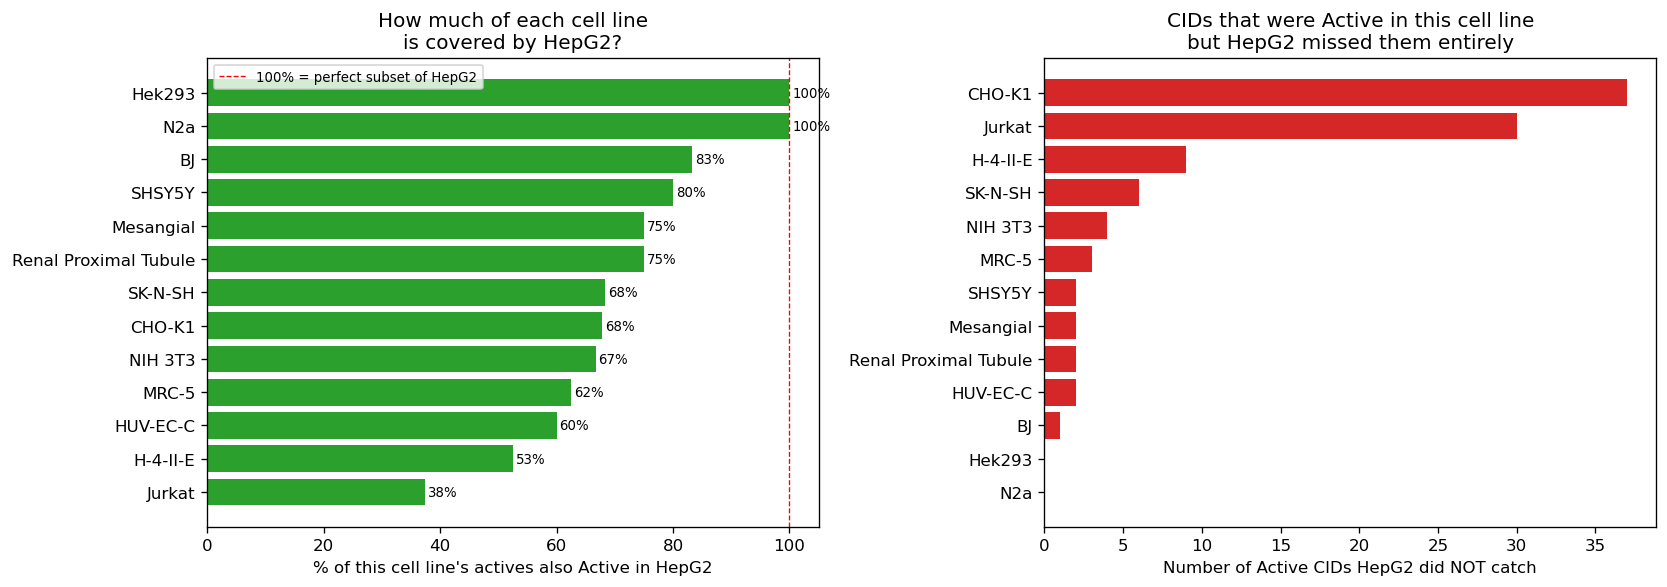


=== SUBSET RELATIONSHIP ===
Cell lines where 100% of their actives are ALSO active in HepG2 (perfect subsets):
  Hek293                     (17 shared active CIDs)
  N2a                        (7 shared active CIDs)

Cell lines with CIDs HepG2 MISSED (HepG2 is not the full picture):
  CHO-K1                     37 CIDs HepG2 did not catch
  Jurkat                     30 CIDs HepG2 did not catch
  H-4-II-E                   9 CIDs HepG2 did not catch
  SK-N-SH                    6 CIDs HepG2 did not catch
  NIH 3T3                    4 CIDs HepG2 did not catch
  MRC-5                      3 CIDs HepG2 did not catch
  SHSY5Y                     2 CIDs HepG2 did not catch
  Mesangial                  2 CIDs HepG2 did not catch
  Renal Proximal Tubule      2 CIDs HepG2 did not catch
  HUV-EC-C                   2 CIDs HepG2 did not catch
  BJ                         1 CIDs HepG2 did not catch


In [18]:
hepg2_col  = 'combined_hepg2_casepase.csv'
hepg2_set  = set(df.loc[df[hepg2_col] == 'Active', 'PUBCHEM_CID'])
other_cols = [c for c in ASSAY_COLS if c != hepg2_col]

rows = []
for c in other_cols:
    other_set   = set(df.loc[df[c] == 'Active', 'PUBCHEM_CID'])
    if not other_set:
        continue

    shared           = other_set & hepg2_set          # active in BOTH
    only_other       = other_set - hepg2_set           # other catches, HepG2 misses
    only_hepg2       = hepg2_set - other_set           # HepG2 catches, other misses

    pct_other_in_h2  = 100 * len(shared) / len(other_set)        # what % of other's actives HepG2 also sees
    pct_h2_in_other  = 100 * len(shared) / len(hepg2_set)        # what % of HepG2's actives the other also sees

    rows.append({
        'cell_line'          : SHORT.get(c, c),
        'n_active_other'     : len(other_set),
        'n_active_hepg2'     : len(hepg2_set),
        'n_shared'           : len(shared),
        'pct_other_in_HepG2' : round(pct_other_in_h2, 1),   # ← how much of THIS cell line is covered by HepG2
        'pct_HepG2_in_other' : round(pct_h2_in_other, 1),   # ← how much of HepG2 is covered by THIS
        'unique_to_other'    : len(only_other),              # HepG2 MISSED these
    })

rel = pd.DataFrame(rows).sort_values('pct_other_in_HepG2', ascending=False)

print("HepG2 relationship to every other cell line:\n")
print(rel.to_string(index=False))

# ── Chart 1: % of each cell line's actives that HepG2 also caught ─────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
bars = ax.barh(rel['cell_line'][::-1], rel['pct_other_in_HepG2'][::-1], color='#2ca02c')
ax.axvline(100, color='red', linestyle='--', linewidth=0.8, label='100% = perfect subset of HepG2')
ax.set_xlabel('% of this cell line\'s actives also Active in HepG2')
ax.set_title('How much of each cell line\nis covered by HepG2?')
ax.legend(fontsize=8)
for bar, val in zip(bars, rel['pct_other_in_HepG2'][::-1]):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{val:.0f}%', va='center', fontsize=8)

# ── Chart 2: how many CIDs HepG2 missed per cell line ─────────────────────────
ax2 = axes[1]
missed = rel.sort_values('unique_to_other', ascending=False)
ax2.barh(missed['cell_line'][::-1], missed['unique_to_other'][::-1], color='#d62728')
ax2.set_xlabel('Number of Active CIDs HepG2 did NOT catch')
ax2.set_title('CIDs that were Active in this cell line\nbut HepG2 missed them entirely')

plt.tight_layout()
plt.show()

# ── Print: which cell lines are true subsets of HepG2 ─────────────────────────
print("\n=== SUBSET RELATIONSHIP ===")
print("Cell lines where 100% of their actives are ALSO active in HepG2 (perfect subsets):")
subsets = rel[rel['pct_other_in_HepG2'] == 100.0]
if len(subsets):
    for _, r in subsets.iterrows():
        print(f"  {r['cell_line']:25s}  ({int(r['n_shared'])} shared active CIDs)")
else:
    print("  None — no cell line is a perfect subset of HepG2")

print("\nCell lines with CIDs HepG2 MISSED (HepG2 is not the full picture):")
missed_any = rel[rel['unique_to_other'] > 0].sort_values('unique_to_other', ascending=False)
for _, r in missed_any.iterrows():
    print(f"  {r['cell_line']:25s}  {int(r['unique_to_other'])} CIDs HepG2 did not catch")

In [19]:
# Filter the DataFrame for CID 299
cid_299_data = df[df['PUBCHEM_CID'] == 299]

# Display the data for CID 299
if not cid_299_data.empty:
    print(cid_299_data)
else:
    print("CID 299 not found in the dataset.")

      PUBCHEM_CID   AID_1346980       AID_655       AID_656       AID_657  \
7703          299  Inconclusive  Inconclusive  Inconclusive  Inconclusive   

           AID_658       AID_659       AID_660       AID_661       AID_663  \
7703  Inconclusive  Inconclusive  Inconclusive  Inconclusive  Inconclusive   

     AID_664       AID_665   AID_666       AID_667  \
7703  Active  Inconclusive  Inactive  Inconclusive   

     combined_hepg2_casepase.csv  \
7703                      Active   

                                                pattern  \
7703  AID_1346980=Inconclusive | AID_655=Inconclusiv...   

                                      behavior  
7703  Mixed (Active + Inactive + Inconclusive)  


In [20]:
# Filter rows where all assay columns are not null
tested_in_all = df[df[ASSAY_COLS].notna().all(axis=1)]

# Display the filtered DataFrame
print(f"Number of CIDs tested in all cell lines: {len(tested_in_all)}")
print(tested_in_all)

Number of CIDs tested in all cell lines: 1272
      PUBCHEM_CID   AID_1346980       AID_655       AID_656       AID_657  \
5897           11      Inactive      Inactive      Inactive      Inactive   
5898           13      Inactive      Inactive      Inactive      Inactive   
5899           51      Inactive      Inactive      Inactive      Inactive   
5900           66      Inactive      Inactive      Inactive      Inactive   
5901          174      Inactive      Inactive      Inactive      Inactive   
...           ...           ...           ...           ...           ...   
7699         1752  Inconclusive  Inconclusive      Inactive  Inconclusive   
7700        19996  Inconclusive  Inconclusive      Inactive  Inconclusive   
7701      6436079  Inconclusive  Inconclusive  Inconclusive  Inconclusive   
7702       171660  Inconclusive  Inconclusive  Inconclusive  Inconclusive   
7703          299  Inconclusive  Inconclusive  Inconclusive  Inconclusive   

           AID_658       AID_

In [21]:

# Count the number of Active, Inactive, and Inconclusive for each cell line
summary = []
for col in ASSAY_COLS:
    active_count = (df[col] == 'Active').sum()
    inactive_count = (df[col] == 'Inactive').sum()
    inconclusive_count = (df[col] == 'Inconclusive').sum()
    total_tested = active_count + inactive_count + inconclusive_count
    active_rate = (active_count / total_tested) * 100 if total_tested > 0 else 0

    summary.append({
        'Cell Line': SHORT.get(col, col),
        'Active': active_count,
        'Inactive': inactive_count,
        'Inconclusive': inconclusive_count,
        'Active Rate (%)': round(active_rate, 2)
    })

# Convert the summary to a DataFrame for better visualization
summary_df = pd.DataFrame(summary)

# Display the summary table
print(summary_df)

                Cell Line  Active  Inactive  Inconclusive  Active Rate (%)
0                  CHO-K1     115      7320           236             1.50
1                  Jurkat      48      1203            82             3.60
2                HUV-EC-C       5      1313            15             0.38
3                  SHSY5Y      10      1286            37             0.75
4                      BJ       6      1301            26             0.45
5                   MRC-5       8      1303            23             0.60
6               Mesangial       8      1299            27             0.60
7                 SK-N-SH      19      1278            37             1.42
8                H-4-II-E      19      1268            46             1.43
9                  Hek293      17      1274            42             1.28
10                    N2a       7      1304            22             0.53
11                NIH 3T3      12      1271            50             0.90
12  Renal Proximal Tubule